<a href="https://colab.research.google.com/github/stefa54sm-ai/Analisi-DataSet/blob/main/Analisi_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [49]:
# ANALISI DEL DATASET NATICUSdroid (Android Permissions)

In [50]:
# installazione delle librerie necessarie
!pip install ucimlrepo matplotlib scikit-learn seaborn numpy pandas

In [51]:
from ucimlrepo import fetch_ucirepo

# Messaggio per confermare l'inizio dell'operazione
print("Scaricamento del dataset in corso...")

# Scarichiamo il dataset NATICUSdroid tramite il suo ID UCI (722)
NATICUSdroid = fetch_ucirepo(id=722)

print("Dataset scaricato con successo!")

Scaricamento del dataset in corso...
Dataset scaricato con successo!


In [52]:
# Organizziamo i dati in tabelle chiamate DataFrame
# X contiene le caratteristiche (la presenza o meno dei permessi nelle app)
X = NATICUSdroid.data.features

# y contiene l'etichetta da prevedere (il risultato: app benigna o malware)
y = NATICUSdroid.data.targets

print("Dati estratti e pronti per l'analisi.")

Dati estratti e pronti per l'analisi.


In [53]:
# Visualizziamo le informazioni generali sul dataset per capire da dove viene
print("--- Informazioni Generali (Metadata) ---")
print(NATICUSdroid.metadata)

--- Informazioni Generali (Metadata) ---
{'uci_id': 722, 'name': 'NATICUSdroid (Android Permissions)', 'repository_url': 'https://archive.ics.uci.edu/dataset/722/naticusdroid+android+permissions+dataset', 'data_url': 'https://archive.ics.uci.edu/static/public/722/data.csv', 'abstract': 'Contains permissions extracted from more than 29000 benign & malware Android apps released between 2010-2019.', 'area': 'Computer Science', 'tasks': ['Classification'], 'characteristics': ['Tabular'], 'num_instances': 29333, 'num_features': 86, 'feature_types': [], 'demographics': [], 'target_col': ['Result'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2021, 'last_updated': 'Tue Apr 09 2024', 'dataset_doi': '10.24432/C5FS64', 'creators': ['Akshay Mathur'], 'intro_paper': {'ID': 122, 'type': 'NATIVE', 'title': 'NATICUSdroid: A malware detection framework for Android using native and custom permissions', 'authors': 'A. Mathur, Laxmi M. Podila,

In [54]:
# Visualizziamo la descrizione di ogni singola colonna
print("\n--- Dettaglio delle Variabili ---")
print(NATICUSdroid.variables)


--- Dettaglio delle Variabili ---
                                                 name     role     type  \
0                     android.permission.GET_ACCOUNTS  Feature  Integer   
1    com.sonyericsson.home.permission.BROADCAST_BADGE  Feature  Integer   
2                     android.permission.READ_PROFILE  Feature  Integer   
3                  android.permission.MANAGE_ACCOUNTS  Feature  Integer   
4              android.permission.WRITE_SYNC_SETTINGS  Feature  Integer   
..                                                ...      ...      ...   
82  com.google.android.finsky.permission.BIND_GET_...  Feature  Integer   
83  com.huawei.android.launcher.permission.READ_SE...  Feature  Integer   
84                        android.permission.READ_SMS  Feature  Integer   
85          android.permission.PROCESS_INCOMING_CALLS  Feature  Integer   
86                                             Result   Target  Integer   

   demographic description units missing_values  
0         None

In [55]:
# Mostriamo le prime 5 righe della tabella X per vedere i valori numerici
print("Anteprima dei dati:")
X.head()

Anteprima dei dati:


,android.permission.GET_ACCOUNTS,com.sonyericsson.home.permission.BROADCAST_BADGE,android.permission.READ_PROFILE,android.permission.MANAGE_ACCOUNTS,android.permission.WRITE_SYNC_SETTINGS,android.permission.READ_EXTERNAL_STORAGE,android.permission.RECEIVE_SMS,com.android.launcher.permission.READ_SETTINGS,android.permission.WRITE_SETTINGS,com.google.android.providers.gsf.permission.READ_GSERVICES,...,android.permission.CLEAR_APP_CACHE,com.android.launcher.permission.UNINSTALL_SHORTCUT,com.sec.android.iap.permission.BILLING,com.htc.launcher.permission.UPDATE_SHORTCUT,com.sec.android.provider.badge.permission.WRITE,android.permission.ACCESS_NETWORK_STATE,com.google.android.finsky.permission.BIND_GET_INSTALL_REFERRER_SERVICE,com.huawei.android.launcher.permission.READ_SETTINGS,android.permission.READ_SMS,android.permission.PROCESS_INCOMING_CALLS
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,0,0,0


---
INIZIAMO AD ANALIZZARE IL DATASET

Per prima cosa vogliamo verificare se il dataset che vogliamo capire è se i malware chiedono più permessi rispetto alle app normali (benigne). In poche parole mettiamo a confronto il numero totale di permessi richiesti dalle app sicure (blu) rispetto ai malware (arancione)

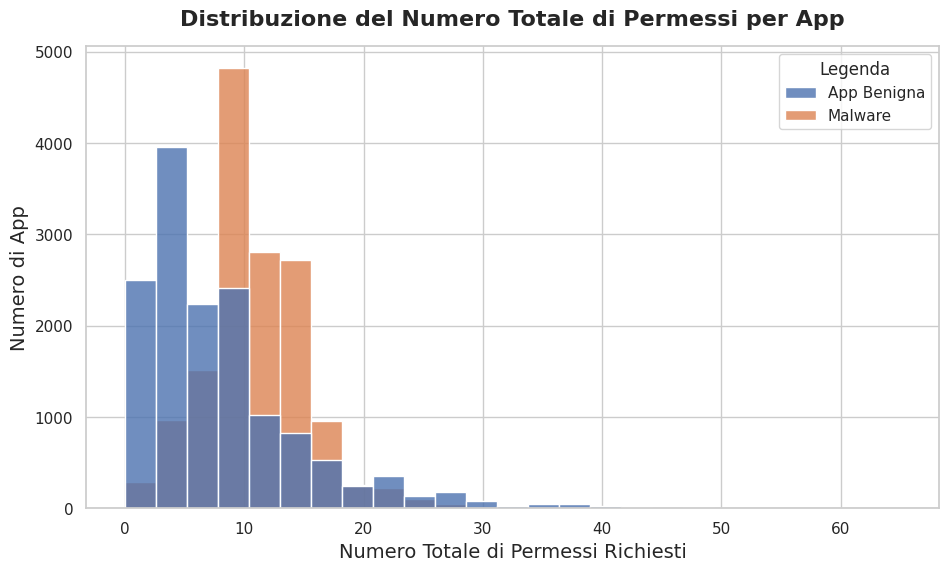

In [56]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Uniamo le caratteristiche (X) e il risultato (y) in un'unica tabella
df = pd.concat([X, y], axis=1)

# Mappiamo i valori della colonna Result per avere etichette chiare nella legenda
# 0 = App Benigna (blu), 1 = Malware (arancione/rosso)
df['Legenda'] = df['Result'].map({0: 'App Benigna', 1: 'Malware'})

# Calcoliamo una nuova colonna: quanti permessi richiede in totale ciascuna app?
# Sommiamo i valori (1) di tutte le colonne dei permessi per ogni riga
df['total_permissions'] = X.sum(axis=1)

# Impostiamo lo stile pulito
sns.set_theme(style="whitegrid")
plt.figure(figsize=(11, 6))

# Creiamo l'istogramma suddividendo i colori in base al target ('Result': malware vs benigno)
# 'multiple="stack"' impila le barre per vedere il totale complessivo e la proporzione
sns.histplot(
    data=df,
    x='total_permissions',
    hue='Legenda',          # Colora diversamente in base al risultato (malware o no)
    bins=25,
    multiple="layer",
    palette=['#4C72B0', '#DD8452'],
    alpha=0.8
)

# Aggiungiamo titolo ed etichette
plt.title('Distribuzione del Numero Totale di Permessi per App', fontsize=16, pad=15, fontweight='bold')
plt.xlabel('Numero Totale di Permessi Richiesti', fontsize=14)
plt.ylabel('Numero di App', fontsize=14)

# Mostriamo il grafico
plt.show()


Ora, per verificare se il grafico precedente sia attendibile dobbiamo capire se il dataset che stiamo analizzando è bilanciato oppure no. Ovvero dobbiamo capire se il numero di malware e di app benigne, all'interno del dataset, è simile. Se il numero è simile allora il dataset è bilanciato e il grafico soprariportato è attendibile altrimenti dobbiamo calibrare in modo differente la nostra analisi

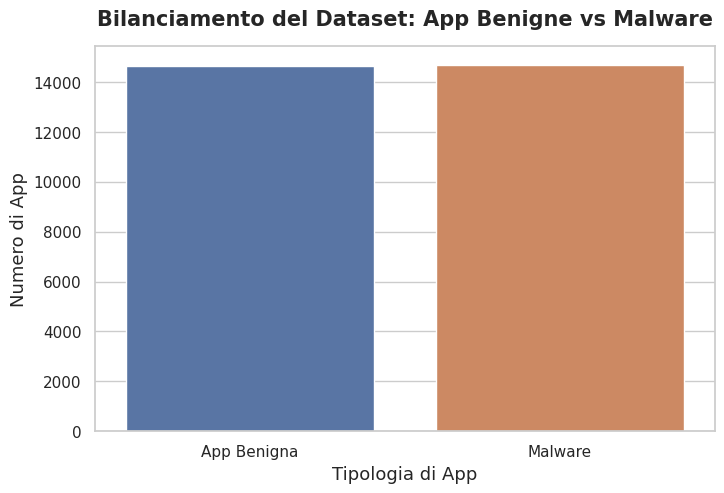

In [57]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Legenda',hue= 'Legenda', palette=['#4C72B0', '#DD8452'], legend = False)
plt.title('Bilanciamento del Dataset: App Benigne vs Malware', fontsize=15, pad=15, fontweight='bold')
plt.xlabel('Tipologia di App', fontsize=13)
plt.ylabel('Numero di App', fontsize=13)
plt.show()

Ora che abbiamo verificato e abbiamo confermato che il dataset sia bilanciato un altro aspetto che vogliamo analizzare è capire quali permessi sono più richiesti dai malware rispetto alle app benigne

<Figure size 1200x600 with 0 Axes>

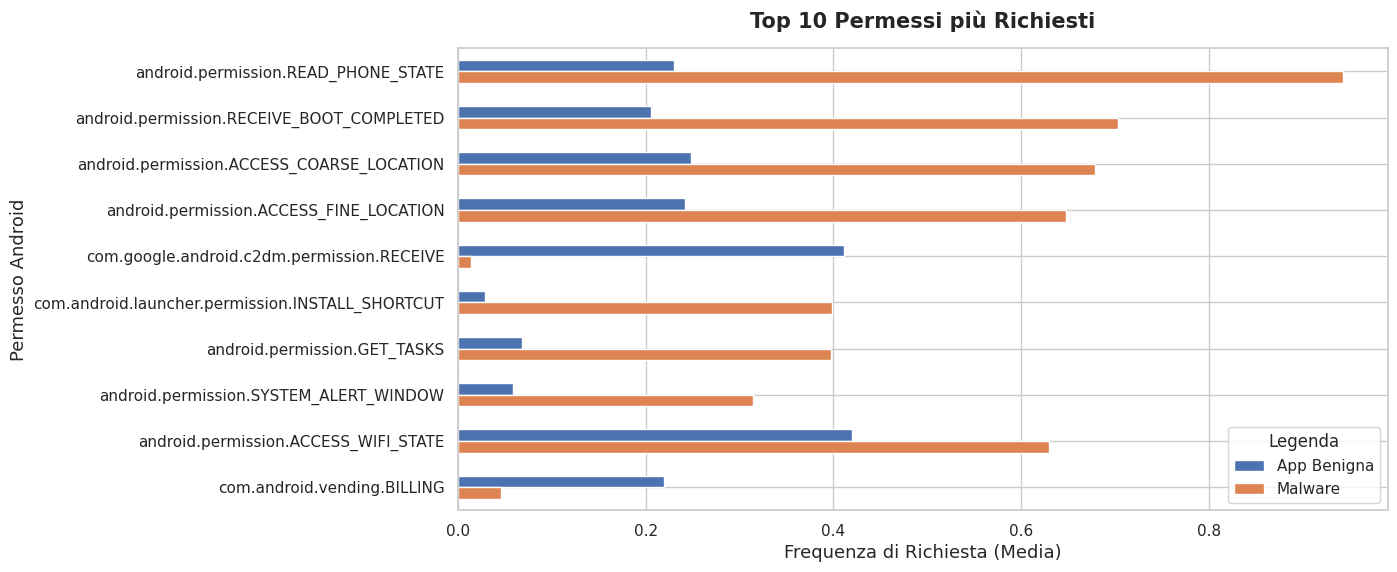

In [58]:
# Calcoliamo la percentuale di richiesta di ciascun permesso per malware e app benigne
perm_columns = X.columns
comparison = df.groupby('Legenda')[perm_columns].mean().T
comparison['Difference'] = abs(comparison['Malware'] - comparison['App Benigna'])

# Prendiamo i 10 permessi con la differenza maggiore (quelli più caratteristici)
top_permissions = comparison.sort_values(by='Difference', ascending=False).head(10)

# Creiamo il grafico a barre orizzontale
plt.figure(figsize=(12, 6))
top_permissions[['App Benigna', 'Malware']].plot(kind='barh', figsize=(12, 6), color=['#4C72B0', '#DD8452'])
plt.title('Top 10 Permessi più Richiesti', fontsize=15, pad=15, fontweight='bold')
plt.xlabel('Frequenza di Richiesta (Media)', fontsize=13)
plt.ylabel('Permesso Android', fontsize=13)
plt.gca().invert_yaxis() # Inverte l'asse per mettere il più importante in cima
plt.legend(title='Legenda')
plt.show()


 ANALISI ESPLORATIVA: QUALITÀ E STRUTTURA DEI DATI

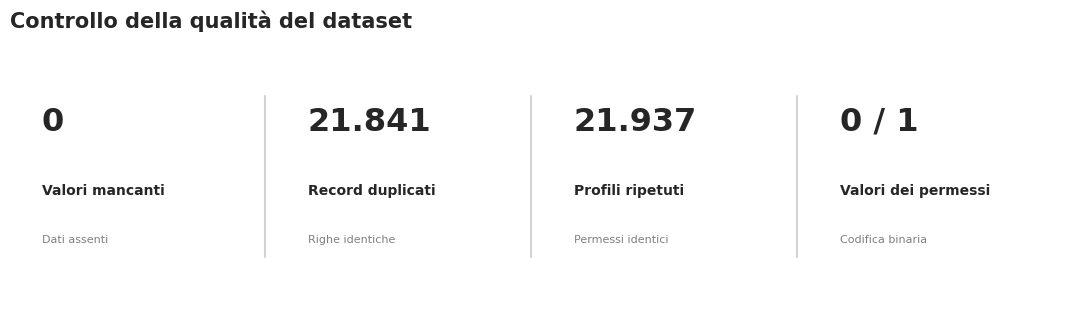

In [59]:

# ANALISI DELLA QUALITÀ DEI DATI

# Calcoliamo gli indicatori
valori_mancanti = df.isnull().sum().sum()
record_duplicati = df.duplicated().sum()
profili_ripetuti = X.duplicated().sum()

# Verifichiamo i valori presenti nelle caratteristiche
valori_permessi = sorted(X.stack().unique())

# Creiamo una visualizzazione sintetica
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.axis("off")

indicatori = [
    ("Valori mancanti", valori_mancanti, "Dati assenti"),
    ("Record duplicati", f"{record_duplicati:,}".replace(",", "."), "Righe identiche"),
    ("Profili ripetuti", f"{profili_ripetuti:,}".replace(",", "."), "Permessi identici"),
    ("Valori dei permessi", " / ".join(map(str, valori_permessi)), "Codifica binaria")
]

for i, (titolo, valore, descrizione) in enumerate(indicatori):
    x_pos = 0.03 + i * 0.25

    ax.text(x_pos, 0.72, str(valore),
            transform=ax.transAxes,
            fontsize=23, fontweight="bold")

    ax.text(x_pos, 0.48, titolo,
            transform=ax.transAxes,
            fontsize=10, fontweight="bold")

    ax.text(x_pos, 0.30, descrizione,
            transform=ax.transAxes,
            fontsize=8, color="gray")

    if i < 3:
        ax.plot([x_pos + 0.21, x_pos + 0.21],
                [0.25, 0.85],
                transform=ax.transAxes,
                color="lightgray")

ax.set_title("Controllo della qualità del dataset",
             fontsize=15, fontweight="bold",
             loc="left", pad=20)

plt.tight_layout()
plt.show()


In [60]:

# VERIFICA DEI PROFILI DI PERMESSI CON ETICHETTE DIVERSE

gruppi = df.groupby(list(X.columns))["Result"].agg(
    numero_app="size",
    numero_classi="nunique"
)

# Individuiamo i profili associati a più di una classe
profili_conflitto = gruppi[gruppi["numero_classi"] > 1]

print("Profili di permessi associati a entrambe le classi:",
      len(profili_conflitto))

print("Applicazioni coinvolte:",
      int(profili_conflitto["numero_app"].sum()))


Profili di permessi associati a entrambe le classi: 96
Applicazioni coinvolte: 5624


In [61]:
# RIEPILOGO DEI PROFILI DI PERMESSI DISCORDANTI

distribuzione_profili = df.groupby(
    list(X.columns)
)["Result"].value_counts().unstack(fill_value=0)

discordanti = distribuzione_profili[
    (distribuzione_profili[0] > 0) &
    (distribuzione_profili[1] > 0)
]

app_benigne = int(discordanti[0].sum())
malware = int(discordanti[1].sum())
totale = app_benigne + malware

print(f"Profili discordanti: {len(discordanti)}")
print(f"App benigne coinvolte: {app_benigne} ({app_benigne/totale:.1%})")
print(f"Malware coinvolti: {malware} ({malware/totale:.1%})")
print(f"Totale applicazioni coinvolte: {totale}")

Profili discordanti: 96
App benigne coinvolte: 4387 (78.0%)
Malware coinvolti: 1237 (22.0%)
Totale applicazioni coinvolte: 5624


L'analisi ha individuato 96 profili di permessi associati sia ad applicazioni benigne sia a malware, per un totale di 5.624 applicazioni coinvolte. Di queste, 4.387 sono classificate come benigne e 1.237 come malware.

Questo risultato evidenzia un limite delle informazioni disponibili: applicazioni appartenenti a classi differenti possono presentare configurazioni di permessi identiche. Di conseguenza, il solo insieme dei permessi non permette sempre di distinguere le applicazioni malevole da quelle legittime.

Questa osservazione sarà importante nelle successive analisi di clustering, perché applicazioni con profili identici si trovano nello stesso punto dello spazio delle caratteristiche, anche quando hanno etichette differenti.

In [62]:
# ANALISI DEI PROFILI DI PERMESSI DISTINTI

profili_unici = X.drop_duplicates()

print("Numero totale di applicazioni:", len(X))
print("Numero di profili di permessi distinti:", len(profili_unici))
print("Profili ripetuti:", len(X) - len(profili_unici))

Numero totale di applicazioni: 29332
Numero di profili di permessi distinti: 7395
Profili ripetuti: 21937


Numero di profili distinti: 7395
Profilo più frequente: 2009 applicazioni
Profili presenti una sola volta: 5347


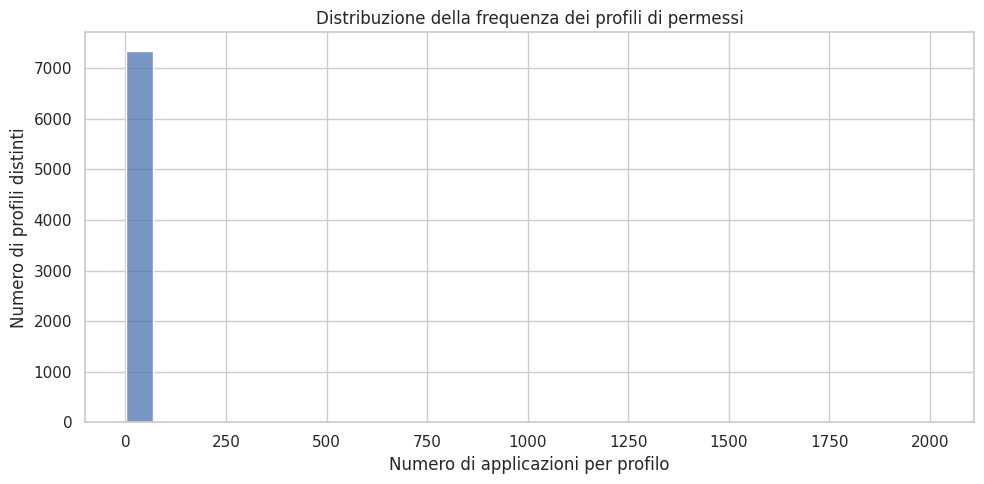

In [63]:
# FREQUENZA DEI PROFILI DI PERMESSI

frequenze_profili = X.value_counts()

print("Numero di profili distinti:", len(frequenze_profili))
print("Profilo più frequente:", frequenze_profili.max(), "applicazioni")
print("Profili presenti una sola volta:", (frequenze_profili == 1).sum())

plt.figure(figsize=(10, 5))

sns.histplot(
    frequenze_profili,
    bins=30,
    color="#4C72B0"
)

plt.title("Distribuzione della frequenza dei profili di permessi")
plt.xlabel("Numero di applicazioni per profilo")
plt.ylabel("Numero di profili distinti")
plt.tight_layout()
plt.show()